The goal of this notebook is to implement a rolling average forecasting model on the telemetry data from Channel P1. We first define a function which plots a rolling average forecast for different window sizes. Then we use these forecasts together with a predetermined threshold in order to determine anomalies in the data. Finally we compare the resulting anomalies to those determined using the LSTM approach. In particular we calculate the precision, recall, and F1 scores for different choices of threshold and window length.

In [1]:
# Install KaggleHub package
%pip install -q kagglehub

Note: you may need to restart the kernel to use updated packages.


In [18]:
import ast
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import kagglehub
from scipy import stats

from datetime import datetime, timedelta
from seaborn import set_style
set_style("whitegrid")

# Download / locate the dataset
base_path = kagglehub.dataset_download(
    "patrickfleith/nasa-anomaly-detection-dataset-smap-msl"
)

labels_path = os.path.join(base_path, "labeled_anomalies.csv")
labels = pd.read_csv(labels_path)

The code below loads the presplit training and test data, and records the anomaly intervals identified in the paper.

In [19]:
def load_signal(channel):
    train = np.load(
        os.path.join(base_path, "data", "data", "train", f"{channel}.npy")
    )[:, 0]
    test = np.load(
        os.path.join(base_path, "data", "data", "test", f"{channel}.npy")
    )[:, 0]
    return train, test

In [20]:
train, test = load_signal("P-1")
intervals = [[2149, 2349], [3539, 3779], [4536, 4844]]
print(len(train),len(test))

2872 8505


The rolling average forecast predicts that the next observed value will be the mean of the previous $k$ observations
$$
y_i = \frac{\hat{y_{i-1}}+ \dots + \hat{y_{i-k}}}{k}
$$

In [21]:
def rolling_average_forecast(train,test,window):
    
    data=np.concatenate((train[-window:],test))
    
    prediction=np.mean(train[-window:])
    
    forecast=np.zeros(len(test))
    
    for i in range(len(test)):
        
        forecast[i]=prediction
        
        prediction+=(test[i]-data[i])/window
        
    return forecast

In [22]:
def plot_forecast(train,test,window):
    forecast=rolling_average_forecast(train,test,window)
    
    plt.figure(figsize=(12, 4))
    
    plt.plot(np.arange(len(train)),train)
    
    plt.plot(np.arange(len(train),len(train)+len(test)),test)
        
    plt.plot(np.arange(len(train),len(train)+len(test)),forecast)
        
    plt.xlabel("Time index")
        
    plt.ylabel("Telemetry value")
        
    plt.title("P-1 Rolling Forecast with a window of length  "+str(window))

Below we plot the resulting forecasts for a variety of window lengths. When the window length is small the forecast values have a high variance. As the window the result forecast becomes centered around the mean of the training data. When the window length is equal to the size of the training set the resulting forecast is essentially just the average forecast.

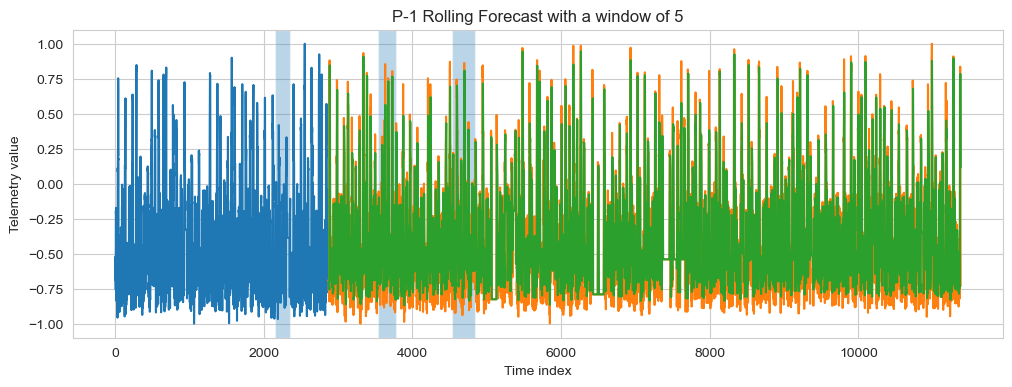

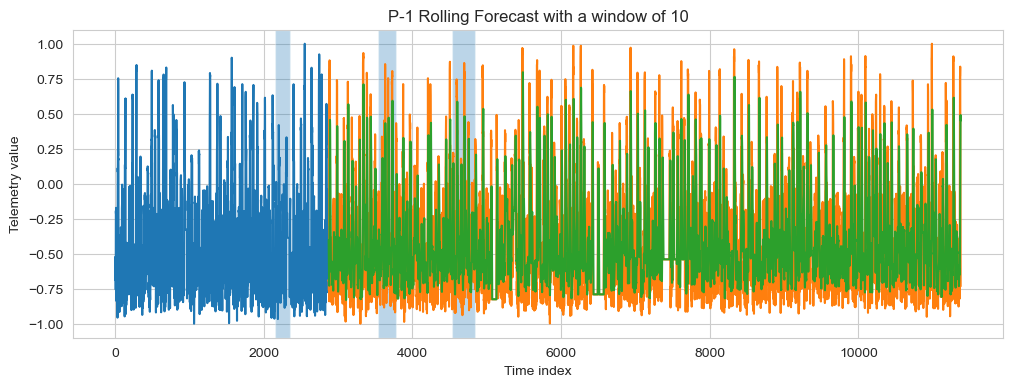

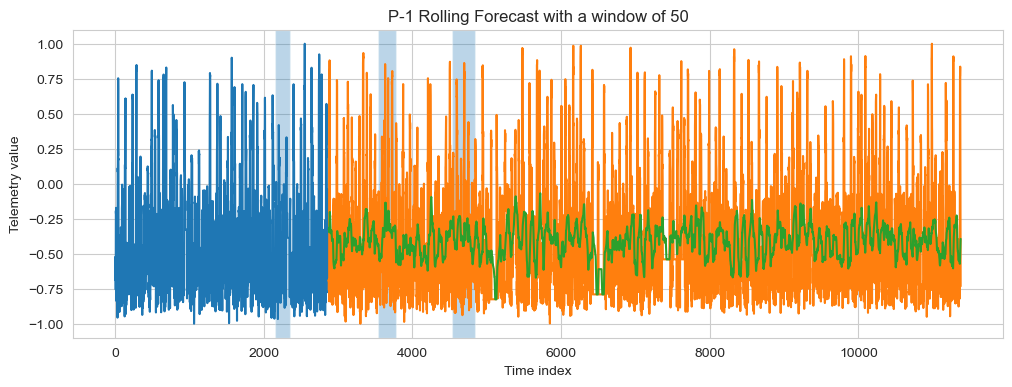

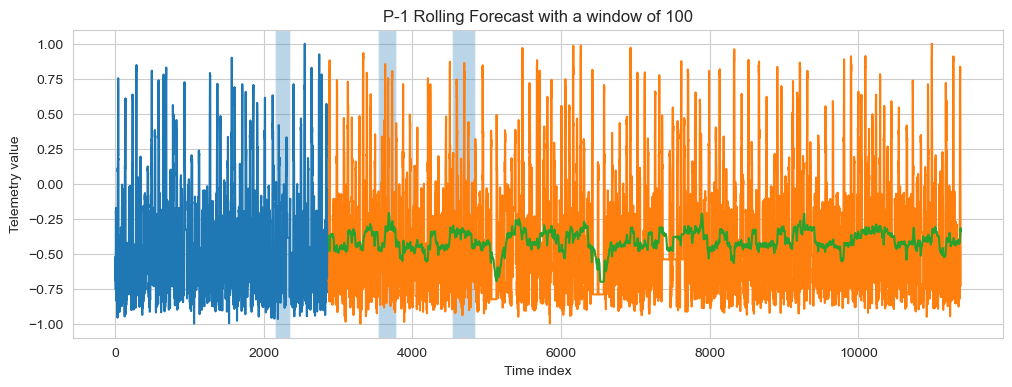

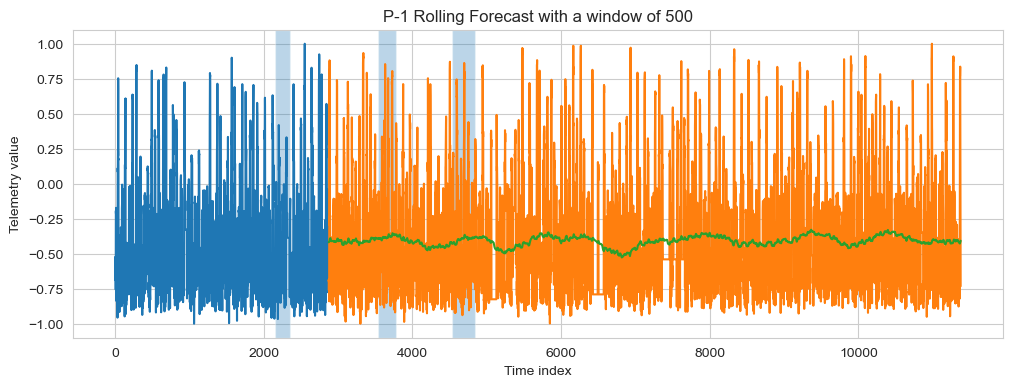

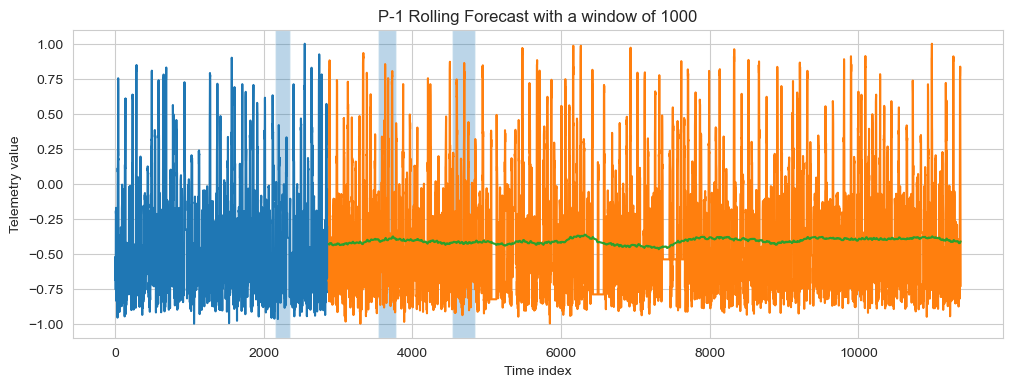

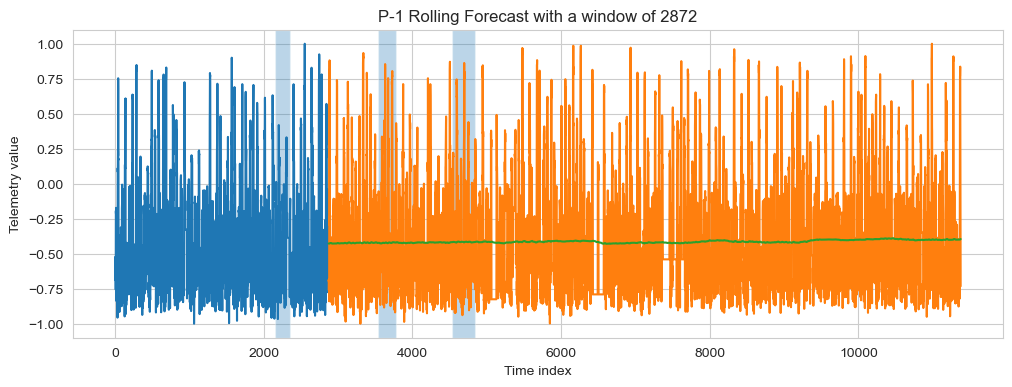

In [7]:
for window in [5,10,50,100,500,1000,len(train)]:
    plot_forecast(train,test,window)
    for start, end in intervals:
        plt.axvspan(start, end, alpha=0.3)
    plt.show()

Next we can plot the residuals $e_t=\hat{y_t}-y_t$ and plot their absolute values $\lvert e_t \rvert$. Since all the anomalies are contained in the time interval $[2000,5000]$, we only plot the residuals for this interval.

In [8]:
def plot_residuals(train,test,window):
    forecast=rolling_average_forecast(train,test,window)
    residuals=test-forecast
    
    plt.figure(figsize=(12,4))

    plt.plot(np.arange(2000,5000),residuals[2000:5000])

    plt.xlabel('Time Index')

    plt.ylabel('Residual')

    plt.title('Residuals from forecasting using a Rolling Average with window length '+str(window))

    

Below we plot the residuals for a windows of length 50 and 100. We see that there are several points throughout most intervals where the residuals spike, i.e. it doesnt seem that a large residual indicates an anomalous telemetry value. 

However, there are some patterns that emerge among the residuals in the areas marked as anaomalous. In particular, these intervals contain "plateaus" where the residual appears to be close to constant. It is unclear if this is just a coincidence or if something deeper is at work.

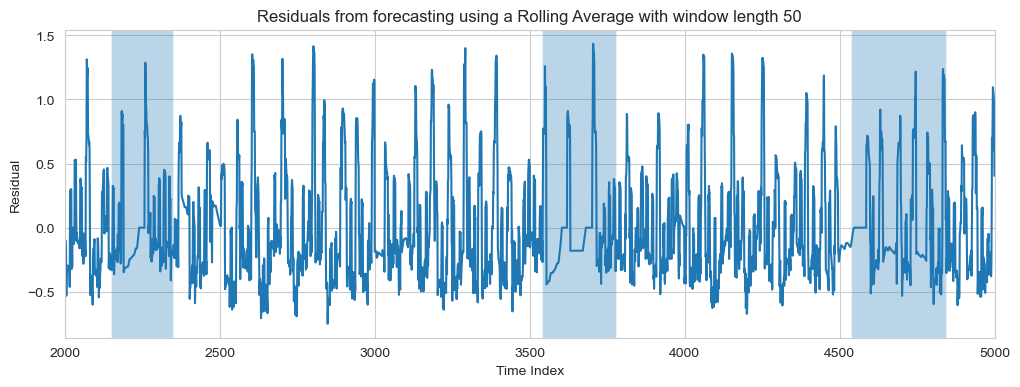

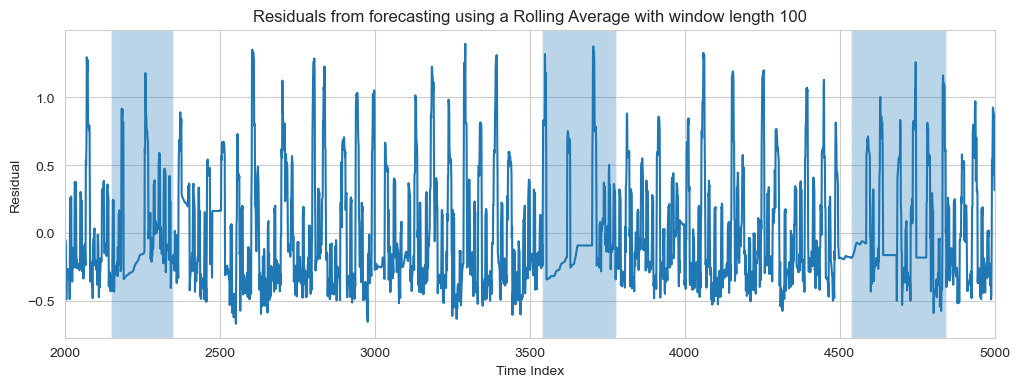

In [23]:
for window in [50,100]:
    plot_residuals(train,test,window)
    for start, end in intervals:
        plt.axvspan(start, end, alpha=0.3)
    plt.xlim(2000, 5000)
    plt.show()

If we plot the absolute value of the residuals we see similar behavior. In particular the anomalous regions contain long stretches in which the magnitude of the residuals are very close to zero. This suggests that we might be able to detect an anomalous region by identifying intervals where the residual value is consistently very small.

In [10]:
def plot_abs_residuals(train,test,window):
    forecast=rolling_average_forecast(train,test,window)
    
    plt.figure(figsize=(12,4))

    plt.plot(np.abs(test-forecast))

    plt.xlabel('Residual')

    plt.ylabel('Residual')

    plt.title('Residuals from forecasting using a Rolling Average with window length '+str(window))

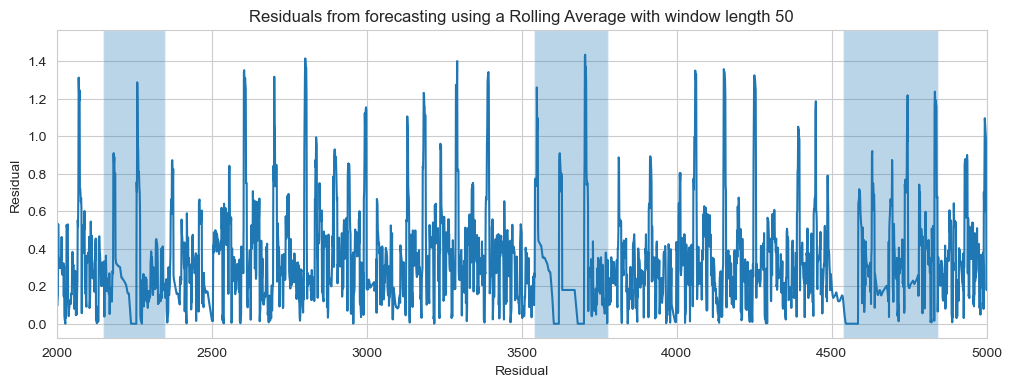

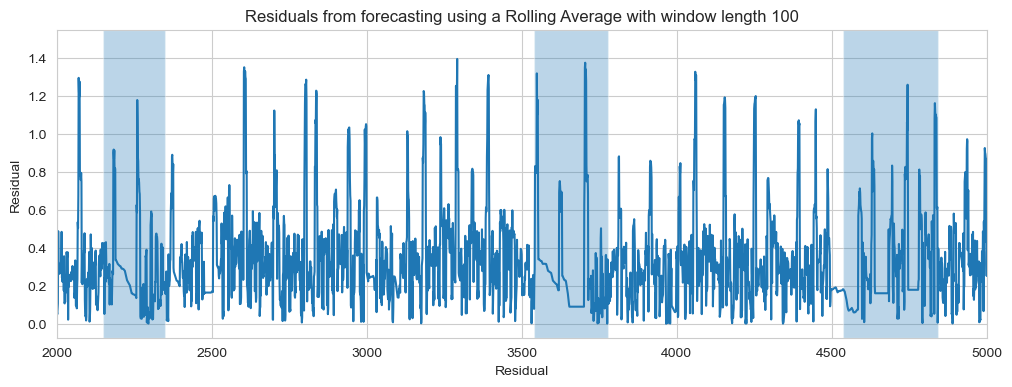

In [11]:
for window in [50,100]:
    plot_abs_residuals(train,test,window)
    for start, end in intervals:
        plt.axvspan(start, end, alpha=0.3)
    plt.xlim(2000, 5000)
    plt.show()

Next we compute some statistics regarding the residuals in the blue region, and the residuals in the white region. One thing that stands out is that in the anamolous regions the median value is significantly smaller.

In [12]:
def compare_residuals(train,test,window):
    forecast=rolling_average_forecast(train,test,window)
    
    residuals = np.abs(test - forecast)

    anomaly_scores = []
    normal_scores = []

    for i, score in enumerate(residuals):
        in_interval = any(start <= i <= end for start, end in intervals)

        if in_interval:
            anomaly_scores.append(score)
        else:
            normal_scores.append(score)

    print('STATISTICS FOR ROLLING AVERAGE FORECAST WITH A WINDOW OF LENGTH '+str(window))
    
    print("Anomaly mean:", np.mean(anomaly_scores))
    print("Normal mean:", np.mean(normal_scores))

    print("Anomaly median:", np.median(anomaly_scores))
    print("Normal median:", np.median(normal_scores))

    print("Anomaly max:", np.max(anomaly_scores))
    print("Normal max:", np.max(normal_scores))

    print("Anomaly std:", np.std(anomaly_scores))
    print("Normal std:", np.std(normal_scores))

    plt.hist(normal_scores, bins=50, alpha=0.5, label="Normal")
    plt.hist(anomaly_scores, bins=50, alpha=0.5, label="Anomaly")
    plt.legend()
    plt.show()

STATISTICS FOR ROLLING AVERAGE FORECAST WITH A WINDOW OF LENGTH 50
Anomaly mean: 0.28439948842304813
Normal mean: 0.33382967261921387
Anomaly median: 0.21728634087685172
Normal median: 0.2911604422839759
Anomaly max: 1.4347618085823468
Normal max: 1.4932410536888612
Anomaly std: 0.26501580866101015
Normal std: 0.24671251409723327


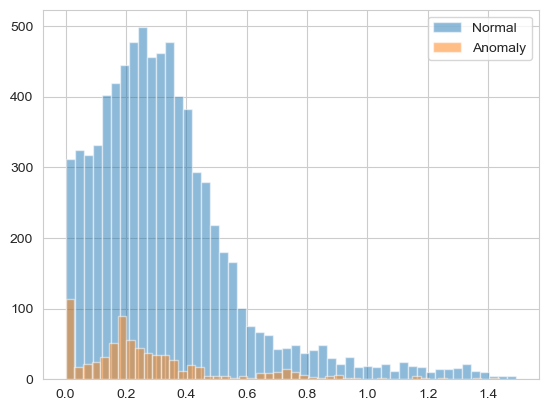

STATISTICS FOR ROLLING AVERAGE FORECAST WITH A WINDOW OF LENGTH 100
Anomaly mean: 0.29465581658945633
Normal mean: 0.33216495670375734
Anomaly median: 0.2173736790026352
Normal median: 0.2913240730141999
Anomaly max: 1.3752929152359346
Normal max: 1.4755400826823868
Anomaly std: 0.2536469527625205
Normal std: 0.23554068182637328


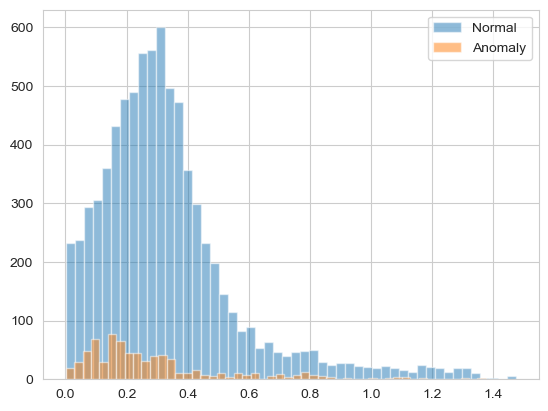

In [13]:
for window in [50,100]:
    compare_residuals(train,test,window)

Next we can define an anomaly detection system which flags points below a certain threshold. We compute the precision, recall, and F1 scores for windows of length 50 and 100 together with various choices of threshold $p$. We see that the highest F1 score occurs for a window length of $50$ and a threshold of $2$.

In [14]:
def compute_anomalies(train,test,window,p):
    forecast=rolling_average_forecast(train,test,window)
    score = abs(test - forecast)
    threshold = np.percentile(score, p)
    return np.where(score < threshold)[0]

In [15]:
def compute_precision_recall(train,test,window,p):
    anomalies=compute_anomalies(train,test,window,p)
    true_positives = [
    x for x in anomalies
    if any(start <= x <= end
           for start, end in intervals)
    ]
    precision=len(true_positives)/len(anomalies)
    recall=len(true_positives)/751
    return precision, recall

In [16]:
for window in [50,100]:
    for p in [1,2,5,10,15,20]:
        print('Precision and Recall for window length of ' + str(window)+ ' and a threshold of ' + str(p)+':', compute_precision_recall(train,test,window,p))

Precision and Recall for window length of 50 and a threshold of 1: (1.0, 0.10252996005326231)
Precision and Recall for window length of 50 and a threshold of 2: (0.5847953216374269, 0.13315579227696406)
Precision and Recall for window length of 50 and a threshold of 5: (0.2676056338028169, 0.151797603195739)
Precision and Recall for window length of 50 and a threshold of 10: (0.1609870740305523, 0.18242343541944075)
Precision and Recall for window length of 50 and a threshold of 15: (0.12774294670846395, 0.2170439414114514)
Precision and Recall for window length of 50 and a threshold of 20: (0.11581422692533803, 0.2623169107856192)
Precision and Recall for window length of 100 and a threshold of 1: (0.11627906976744186, 0.013315579227696404)
Precision and Recall for window length of 100 and a threshold of 2: (0.06432748538011696, 0.014647137150466045)
Precision and Recall for window length of 100 and a threshold of 5: (0.09859154929577464, 0.0559254327563249)
Precision and Recall for w

In [17]:
for window in [50,100]:
    for p in [1,2,5,10,15,20]:
        precision,recall=compute_precision_recall(train,test,window,p)
        F=2*precision*recall/(precision+recall)
        print('F1 score for window length of ' + str(window)+ ' and a threshold of ' + str(p)+':', F) 

F1 score for window length of 50 and a threshold of 1: 0.1859903381642512
F1 score for window length of 50 and a threshold of 2: 0.21691973969631237
F1 score for window length of 50 and a threshold of 5: 0.19371282922684793
F1 score for window length of 50 and a threshold of 10: 0.17103620474406991
F1 score for window length of 50 and a threshold of 15: 0.16082881105081404
F1 score for window length of 50 and a threshold of 20: 0.16068515497553018
F1 score for window length of 100 and a threshold of 1: 0.023894862604540025
F1 score for window length of 100 and a threshold of 2: 0.02386117136659436
F1 score for window length of 100 and a threshold of 5: 0.0713678844519966
F1 score for window length of 100 and a threshold of 10: 0.12983770287141072
F1 score for window length of 100 and a threshold of 15: 0.179575727676369
F1 score for window length of 100 and a threshold of 20: 0.17210440456769982


A next step could be to tweak the anomaly detection system so that it detects entire intervals rather than just points.